In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_o = pd.read_csv('orders_clean.csv')
df_rt = pd.read_csv('returns_clean.csv')
df_s = pd.read_csv('sellers_clean.csv')

In [3]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       29951 non-null  str    
 1   customer_id    29065 non-null  str    
 2   order_date     29951 non-null  str    
 3   product_id     29951 non-null  str    
 4   seller_id      29951 non-null  str    
 5   quantity       29951 non-null  int64  
 6   list_price     29951 non-null  float64
 7   discount_pct   29951 non-null  int64  
 8   sales_amount   29951 non-null  float64
 9   cost_amount    29951 non-null  float64
 10  profit         29951 non-null  float64
 11  order_status   29951 non-null  str    
 12  shipping_days  29951 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 4.2 MB


In [4]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [5]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      2092 non-null   str    
 1   order_id       2092 non-null   str    
 2   product_id     2092 non-null   str    
 3   return_date    2092 non-null   str    
 4   return_reason  2092 non-null   str    
 5   refund_amount  2092 non-null   float64
 6   sales_amount   2092 non-null   float64
dtypes: float64(2), str(5)
memory usage: 200.0 KB


In [7]:
df_rt['return_date'] = pd.to_datetime(df_rt['return_date'])

In [8]:
df_s.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   seller_id      200 non-null    str    
 1   seller_name    200 non-null    str    
 2   seller_state   200 non-null    str    
 3   seller_rating  200 non-null    float64
 4   join_date      200 non-null    str    
dtypes: float64(1), str(4)
memory usage: 14.5 KB


In [10]:
df_s['join_date'] = pd.to_datetime(df_s['join_date'])

In [11]:
df_s.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   seller_id      200 non-null    str           
 1   seller_name    200 non-null    str           
 2   seller_state   200 non-null    str           
 3   seller_rating  200 non-null    float64       
 4   join_date      200 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 12.5 KB


In [12]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   return_id      2092 non-null   str           
 1   order_id       2092 non-null   str           
 2   product_id     2092 non-null   str           
 3   return_date    2092 non-null   datetime64[us]
 4   return_reason  2092 non-null   str           
 5   refund_amount  2092 non-null   float64       
 6   sales_amount   2092 non-null   float64       
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 179.6 KB


In [13]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       29951 non-null  str           
 1   customer_id    29065 non-null  str           
 2   order_date     29951 non-null  datetime64[us]
 3   product_id     29951 non-null  str           
 4   seller_id      29951 non-null  str           
 5   quantity       29951 non-null  int64         
 6   list_price     29951 non-null  float64       
 7   discount_pct   29951 non-null  int64         
 8   sales_amount   29951 non-null  float64       
 9   cost_amount    29951 non-null  float64       
 10  profit         29951 non-null  float64       
 11  order_status   29951 non-null  str           
 12  shipping_days  29951 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(2), str(5)
memory usage: 3.9 MB


Which Seller has HIgh Return Rate?

In [14]:
df_rt.columns

Index(['return_id', 'order_id', 'product_id', 'return_date', 'return_reason',
       'refund_amount', 'sales_amount'],
      dtype='str')

In [15]:
df_o.columns

Index(['order_id', 'customer_id', 'order_date', 'product_id', 'seller_id',
       'quantity', 'list_price', 'discount_pct', 'sales_amount', 'cost_amount',
       'profit', 'order_status', 'shipping_days'],
      dtype='str')

In [16]:
df_s.columns

Index(['seller_id', 'seller_name', 'seller_state', 'seller_rating',
       'join_date'],
      dtype='str')

### 1.  Orders per seller

In [17]:
delivered = df_o[df_o['order_status'] != 'Cancelled']

In [19]:
sell = delivered.groupby('seller_id').agg(delivered = ('order_id', 'count'), revenue = ('sales_amount', 'sum')).reset_index()

In [21]:
sell.head()

,seller_id,delivered,revenue
0,S0002,10,961.62
1,S0003,247,240744.45
2,S0004,255,1650104.30
3,S0005,14,46080.94
4,S0006,15,4853.96


### 2. Returns per seller

In [23]:
ret = df_rt.merge(df_o[['order_id', 'seller_id']], on ='order_id')

In [25]:
ret.head()

,return_id,order_id,product_id,return_date,return_reason,refund_amount,sales_amount,seller_id
0,RET01729,O024764,P0172,2023-07-21,Size/Fit Issue,2441.66,2441.66,S0096
1,RET01379,O019631,P0206,2024-03-09,Wrong Item,770.10,770.10,S0126
2,RET00985,O013896,P0419,2023-10-19,Defective,1469.72,1469.72,S0164
3,RET00242,O003589,P0339,2025-01-15,Defective,9756.60,9756.60,S0197
4,RET00135,O002037,P0172,2023-05-16,Defective,1953.33,1953.33,S0096


In [30]:
ret_count = ret.groupby('seller_id').size().rename('returns').reset_index()

In [32]:
ret_count.head()

,seller_id,returns
0,S0003,25
1,S0004,19
2,S0005,2
3,S0008,24
4,S0009,3


### 3. Return rate

In [33]:
sell.columns

Index(['seller_id', 'delivered', 'revenue'], dtype='str')

In [34]:
ret_count.columns

Index(['seller_id', 'returns'], dtype='str')

In [35]:
df = sell.merge(ret_count, on = 'seller_id', how = 'left').fillna({'returns':0})

In [37]:
df.head()

,seller_id,delivered,revenue,returns
0,S0002,10,961.62,0.0
1,S0003,247,240744.45,25.0
2,S0004,255,1650104.30,19.0
3,S0005,14,46080.94,2.0
4,S0006,15,4853.96,0.0


In [38]:
df['return_rate'] = df['returns']/df['delivered']*100

In [39]:
df.head()

,seller_id,delivered,revenue,returns,return_rate
0,S0002,10,961.62,0.0,0.000000
1,S0003,247,240744.45,25.0,10.121457
2,S0004,255,1650104.30,19.0,7.450980
3,S0005,14,46080.94,2.0,14.285714
4,S0006,15,4853.96,0.0,0.000000


In [40]:
df = df.merge(df_s[['seller_id', 'seller_rating', 'seller_state']], on = 'seller_id')

In [41]:
df.head()

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state
0,S0002,10,961.62,0.0,0.000000,3.6,Karnataka
1,S0003,247,240744.45,25.0,10.121457,5.0,Tamil Nadu
2,S0004,255,1650104.30,19.0,7.450980,4.2,Tamil Nadu
3,S0005,14,46080.94,2.0,14.285714,4.2,Uttar Pradesh
4,S0006,15,4853.96,0.0,0.000000,4.1,Kerala


In [43]:
overall = len(df_rt)/ len(delivered)* 100

In [44]:
overall

7.531953195319533

In [45]:
print('Overall return rate %:', round(overall, 1))

Overall return rate %: 7.5


### 4. Sellers with high return rates

In [46]:
big = df[df['delivered'] >= 100].copy()

In [48]:
big.head()

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state
1,S0003,247,240744.45,25.0,10.121457,5.0,Tamil Nadu
2,S0004,255,1650104.30,19.0,7.450980,4.2,Tamil Nadu
6,S0008,375,510167.54,24.0,6.400000,3.3,Tamil Nadu
8,S0010,129,451675.42,7.0,5.426357,4.7,Gujarat
10,S0013,398,503791.54,30.0,7.537688,3.5,Rajasthan


In [49]:
# and also return rate must be > 10 according to me.

In [50]:
big['high'] = big['return_rate']>10

In [51]:
big.head()

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state,high
1,S0003,247,240744.45,25.0,10.121457,5.0,Tamil Nadu,True
2,S0004,255,1650104.30,19.0,7.450980,4.2,Tamil Nadu,False
6,S0008,375,510167.54,24.0,6.400000,3.3,Tamil Nadu,False
8,S0010,129,451675.42,7.0,5.426357,4.7,Gujarat,False
10,S0013,398,503791.54,30.0,7.537688,3.5,Rajasthan,False


In [52]:
top = big.sort_values('return_rate', ascending = False)

In [53]:
top.head()

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state,high
63,S0070,140,2180546.69,17.0,12.142857,4.5,Tamil Nadu,True
85,S0093,159,934457.31,19.0,11.949686,3.5,West Bengal,True
57,S0064,155,150177.49,18.0,11.612903,4.2,Rajasthan,True
69,S0076,139,794311.55,16.0,11.510791,3.2,Kerala,True
127,S0137,122,278334.44,14.0,11.475410,4.3,Gujarat,True


In [54]:
top.shape

(69, 8)

In [55]:
print(top[['seller_id', 'delivered', 'returns', 'return_rate', 'revenue', 'seller_rating']].round(1))

    seller_id  delivered  returns  return_rate    revenue  seller_rating
63      S0070        140     17.0         12.1  2180546.7            4.5
85      S0093        159     19.0         11.9   934457.3            3.5
57      S0064        155     18.0         11.6   150177.5            4.2
69      S0076        139     16.0         11.5   794311.6            3.2
127     S0137        122     14.0         11.5   278334.4            4.3
..        ...        ...      ...          ...        ...            ...
95      S0103        168      8.0          4.8   155947.7            3.7
176     S0186        127      6.0          4.7  3469128.6            4.2
40      S0044        333     13.0          3.9  1462833.4            4.7
90      S0098        144      5.0          3.5   332716.6            5.0
179     S0190        128      4.0          3.1   226757.6            5.0

[69 rows x 6 columns]


In [56]:
print('High-return sellers:', big['high'].sum())

High-return sellers: 13


In [57]:
print('Seller rating vs return rate correlation:', round(big['seller_rating'].corr(big['return_rate']), 2))

Seller rating vs return rate correlation: -0.2


## VISUALIZATION

### 1. Top 10 sellers by return rate

In [64]:
top.head(10)

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state,high
63,S0070,140,2180546.69,17.0,12.142857,4.5,Tamil Nadu,True
85,S0093,159,934457.31,19.0,11.949686,3.5,West Bengal,True
57,S0064,155,150177.49,18.0,11.612903,4.2,Rajasthan,True
69,S0076,139,794311.55,16.0,11.510791,3.2,Kerala,True
127,S0137,122,278334.44,14.0,11.475410,4.3,Gujarat,True
44,S0048,254,663925.38,29.0,11.417323,4.2,Kerala,True
88,S0096,1128,4424731.82,123.0,10.904255,3.7,Karnataka,True
48,S0052,199,3619170.55,21.0,10.552764,5.0,Delhi,True
84,S0092,193,602704.98,20.0,10.362694,4.2,Tamil Nadu,True
93,S0101,165,160166.93,17.0,10.303030,2.9,Rajasthan,True


In [66]:
t = top.sort_values('return_rate', ascending = False)

In [67]:
t.head(10)

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state,high
63,S0070,140,2180546.69,17.0,12.142857,4.5,Tamil Nadu,True
85,S0093,159,934457.31,19.0,11.949686,3.5,West Bengal,True
57,S0064,155,150177.49,18.0,11.612903,4.2,Rajasthan,True
69,S0076,139,794311.55,16.0,11.510791,3.2,Kerala,True
127,S0137,122,278334.44,14.0,11.475410,4.3,Gujarat,True
44,S0048,254,663925.38,29.0,11.417323,4.2,Kerala,True
88,S0096,1128,4424731.82,123.0,10.904255,3.7,Karnataka,True
48,S0052,199,3619170.55,21.0,10.552764,5.0,Delhi,True
84,S0092,193,602704.98,20.0,10.362694,4.2,Tamil Nadu,True
93,S0101,165,160166.93,17.0,10.303030,2.9,Rajasthan,True


In [72]:
p = top.sort_values('return_rate')

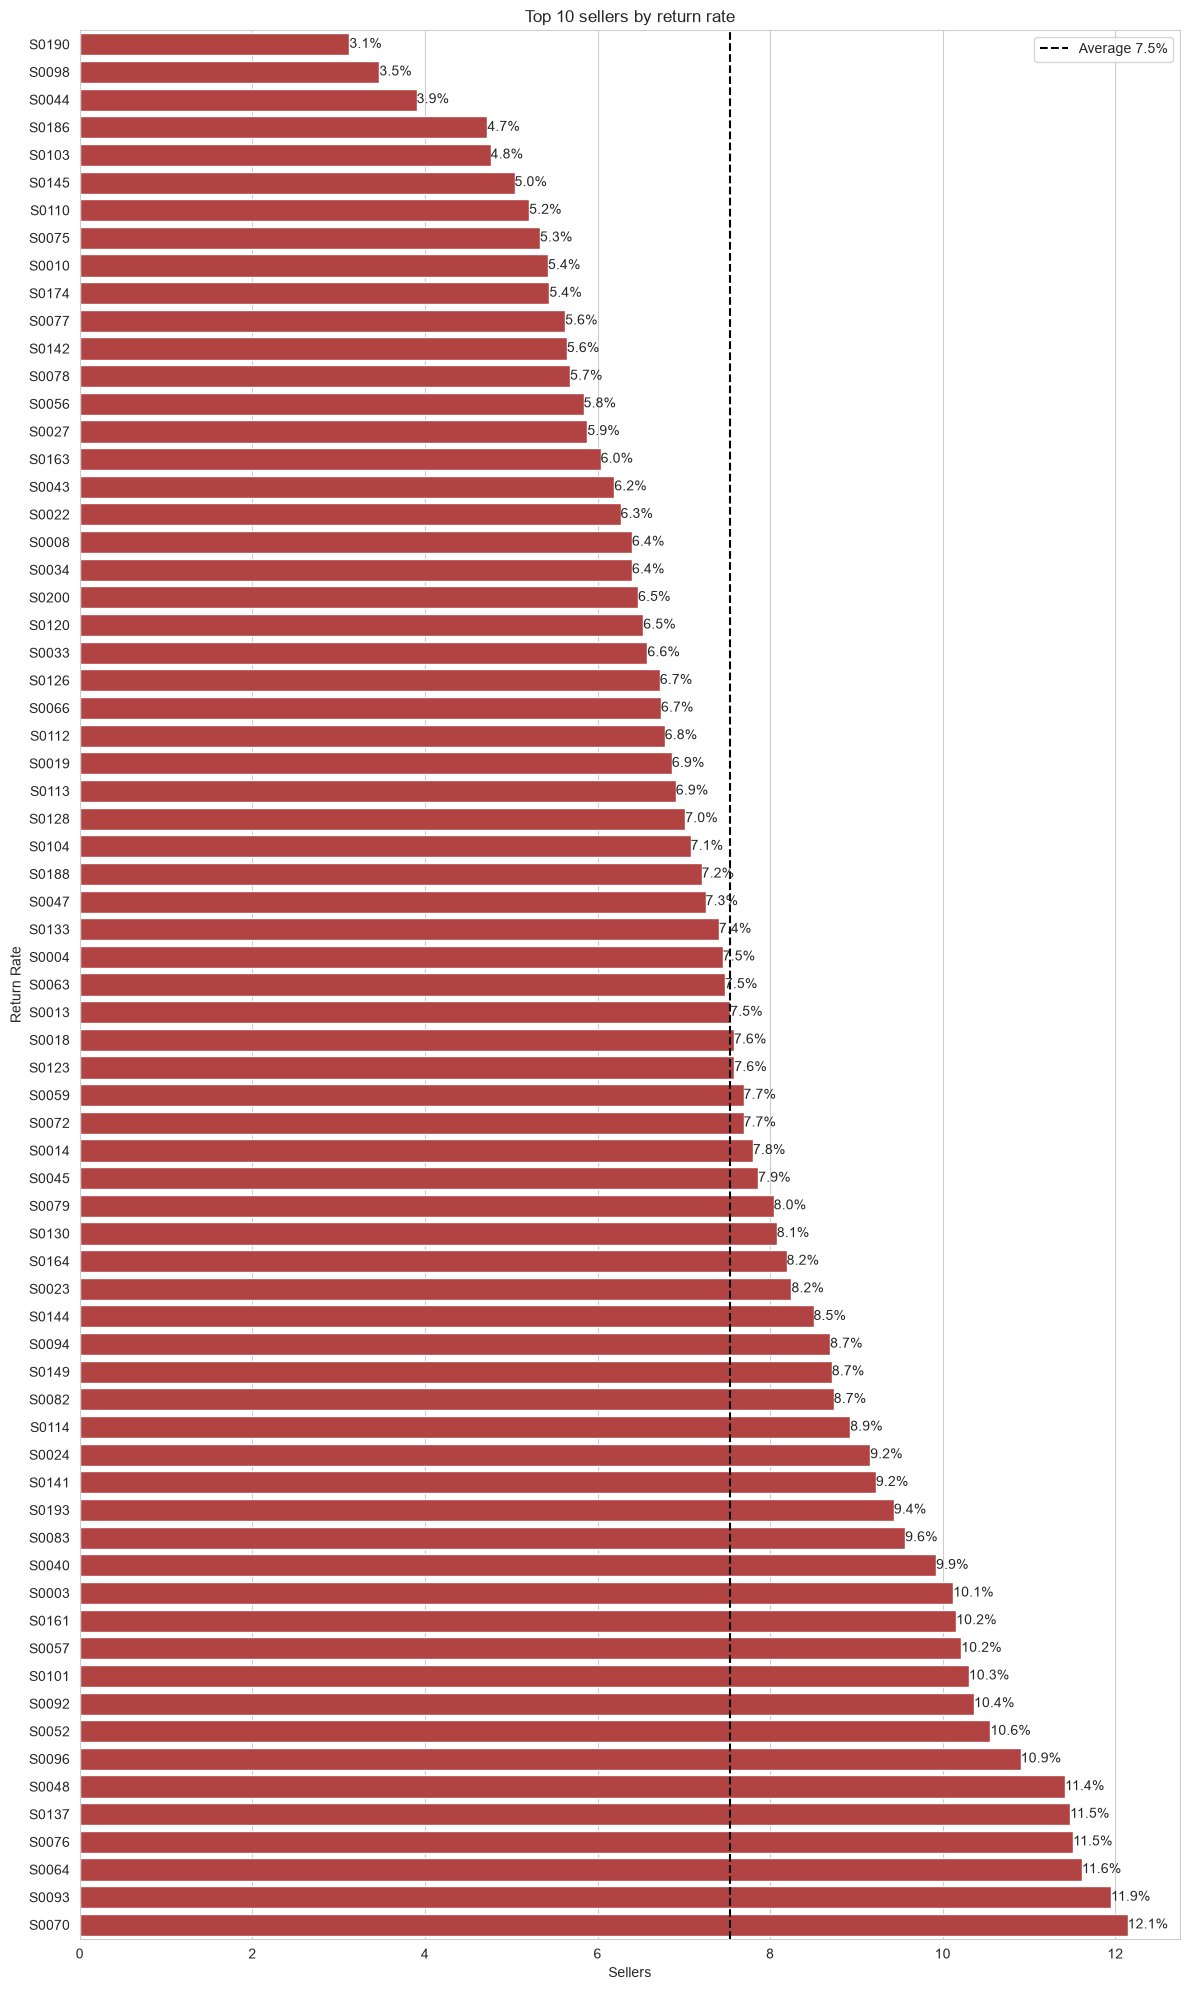

In [94]:
sns.set_style('whitegrid')
plt.figure(figsize=(12,20))
a = sns.barplot(data = p, x='return_rate', y = 'seller_id', color='#c53030')
a.bar_label(a.containers[0], fmt = '%.1f%%')
plt.axvline(overall, color='black', linestyle='--', label=f'Average {overall:.1f}%')
plt.legend(loc='upper right')
plt.title('Top 10 sellers by return rate')
plt.xlabel('Sellers')
plt.ylabel('Return Rate')
plt.tight_layout();
plt.show()

### 2. Revenue vs return rate

In [95]:
big['rev_m'] = big['revenue']/1e6 

In [97]:
big.head()

,seller_id,delivered,revenue,returns,return_rate,seller_rating,seller_state,high,rev_m
1,S0003,247,240744.45,25.0,10.121457,5.0,Tamil Nadu,True,0.240744
2,S0004,255,1650104.30,19.0,7.450980,4.2,Tamil Nadu,False,1.650104
6,S0008,375,510167.54,24.0,6.400000,3.3,Tamil Nadu,False,0.510168
8,S0010,129,451675.42,7.0,5.426357,4.7,Gujarat,False,0.451675
10,S0013,398,503791.54,30.0,7.537688,3.5,Rajasthan,False,0.503792


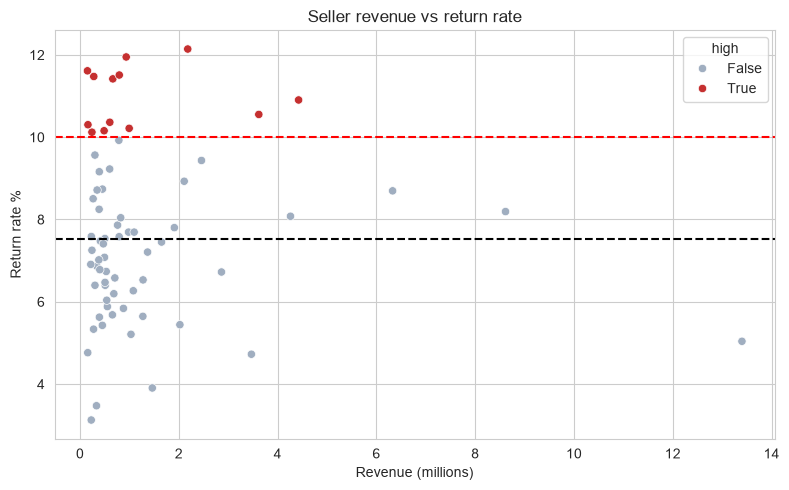

In [108]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=big, x='rev_m', y='return_rate', hue='high',palette={False: '#a0aec0', True: '#c53030'})
plt.axhline(overall, color='black', linestyle='--') # average
plt.axhline(10, color='red', linestyle='--') # high-return line
plt.xlabel('Revenue (millions)')
plt.ylabel('Return rate %')
plt.title('Seller revenue vs return rate')
plt.tight_layout() 
plt.show()

In [ ]:
Most sellers sit between 5% and 10%. 
The red dots above the line are the problem sellers.

### 3. Return rate spreading

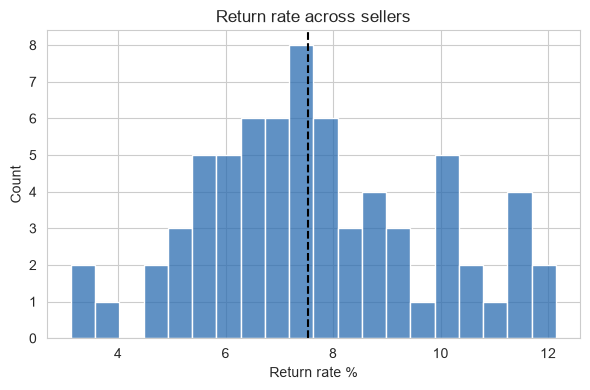

In [109]:
plt.figure(figsize=(6, 4))
sns.histplot(big['return_rate'], bins=20, color='#2b6cb0')
plt.axvline(overall, color='black', linestyle='--')
plt.xlabel('Return rate %')
plt.title('Return rate across sellers')
plt.tight_layout()
plt.show()